DIGITLAB: HANDWRITTEN DIGIT RECOGNITION

EXPERIMENT 1: DATA PREPROCESSING
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Number of classes: 10


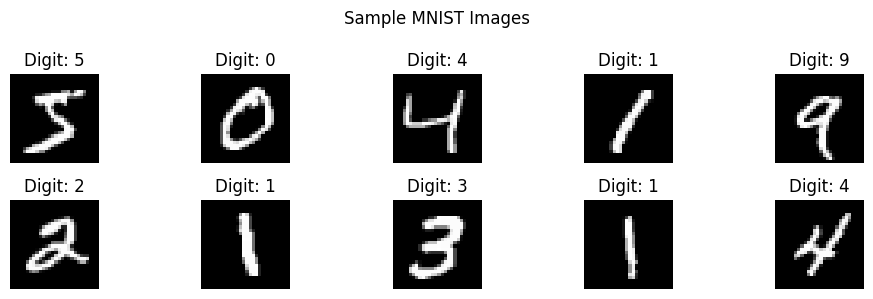


EXPERIMENT 2: SVM AND RANDOM FOREST
SVM Accuracy: 94.05 %
Random Forest Accuracy: 91.25 %

EXPERIMENT 3: DECISION TREE
Decision Tree Accuracy: 74.75 %

EXPERIMENT 4: MODEL COMPARISON


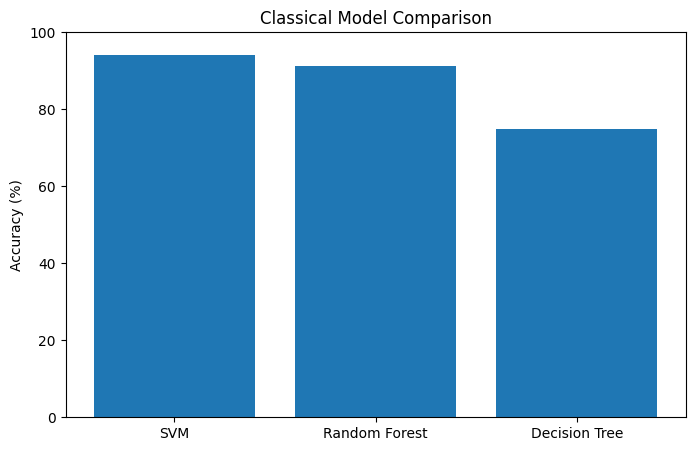

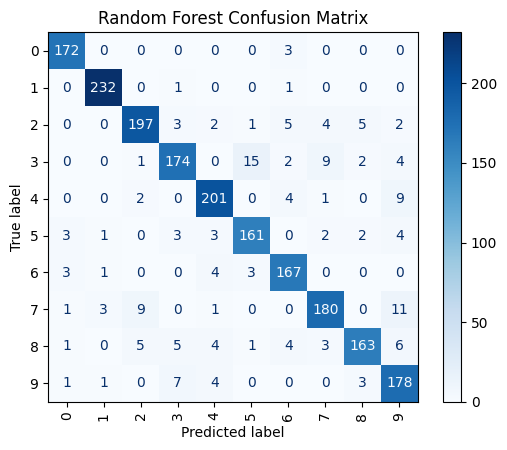


EXPERIMENT 5: K-MEANS CLUSTERING AND PCA


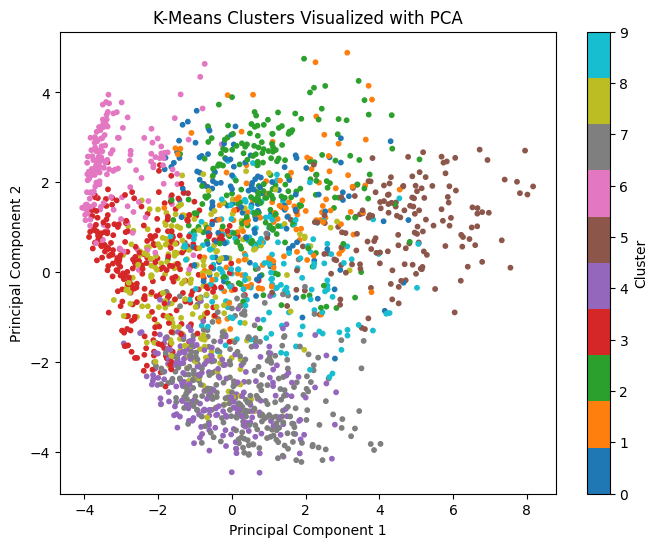

Number of clusters: 10
PCA explained variance: 0.1747

EXPERIMENT 6A: FEEDFORWARD NEURAL NETWORK
Epoch 1/3
85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.7954 - loss: 0.7761 - val_accuracy: 0.8942 - val_loss: 0.3422
Epoch 2/3
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9225 - loss: 0.2777 - val_accuracy: 0.9225 - val_loss: 0.2597
Epoch 3/3
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9409 - loss: 0.2091 - val_accuracy: 0.9375 - val_loss: 0.2237
Feedforward NN Accuracy: 92.28 %

EXPERIMENT 6B: CNN
Epoch 1/3
106/106 ━━━━━━━━━━━━━━━━━━━━ 12s 103ms/step - accuracy: 0.8009 - loss: 0.6502 - val_accuracy: 0.9280 - val_loss: 0.2481
Epoch 2/3
106/106 ━━━━━━━━━━━━━━━━━━━━ 9s 88ms/step - accuracy: 0.9477 - loss: 0.1827 - val_accuracy: 0.9607 - val_loss: 0.1355
Epoch 3/3
106/106 ━━━━━━━━━━━━━━━━━━━━ 11s 101ms/step - accuracy: 0.9650 - loss: 0.1185 - val_accuracy: 0.9640 - val_loss: 0.1167
CNN Test Accuracy: 97.05 %
CNN saved: digitlab_outputs/cnn_model.keras


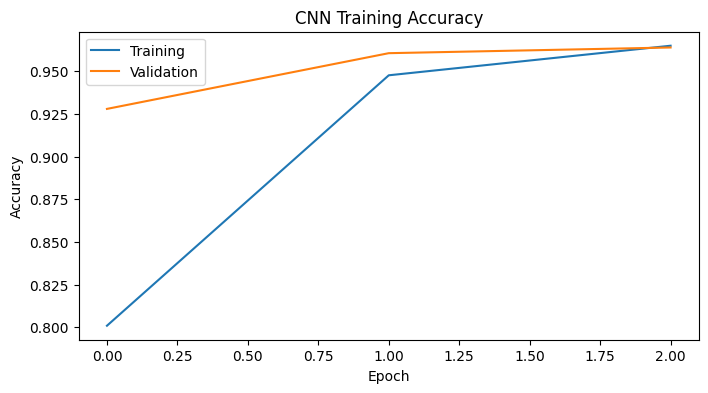

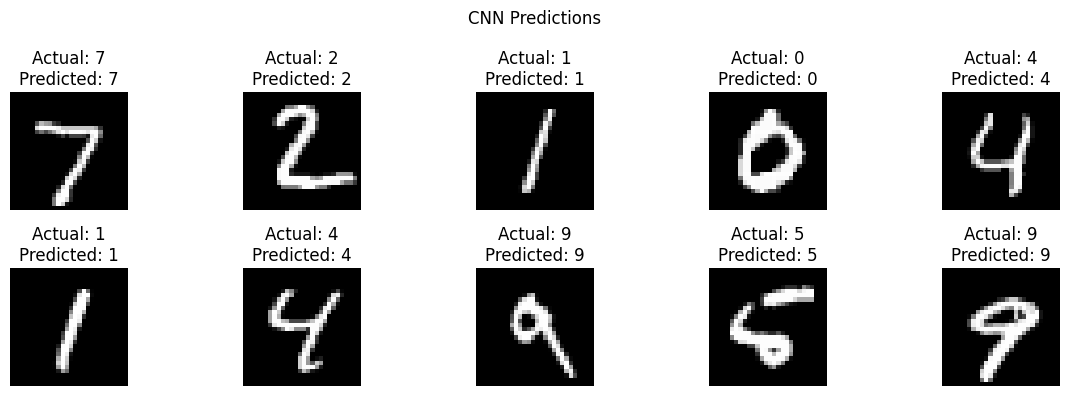


EXPERIMENT 7: GAN IMAGE GENERATION
GAN Epoch 1/2 | Generator Loss: 0.5760 | Discriminator Loss: 1.3541
GAN Epoch 2/2 | Generator Loss: 1.4823 | Discriminator Loss: 0.7453


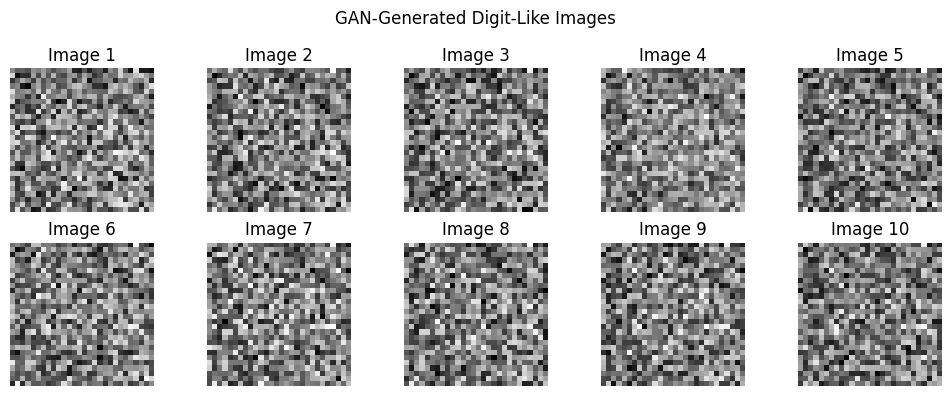


EXPERIMENT 8: SVM GRID SEARCH
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'C': 3, 'kernel': 'rbf'}
Cross-validation accuracy: 93.45 %
Tuned SVM test accuracy: 90.15 %

EXPERIMENT 9: FLASK API AND DOCKER FILES
CNN model is ready: digitlab_outputs/cnn_model.keras


GET /: 200 {'endpoints': ['/', '/health', '/predict'], 'message': 'Handwritten Digit Recognition API', 'project': 'DigitLab'}
GET /health: 200 {'model_loaded': True, 'status': 'healthy'}
POST /predict: 200 {'confidence': 0.9996011853218079, 'predicted_digit': 7, 'probabilities': [2.442541926939157e-06, 3.8895166198926745e-07, 0.00013317538832779974, 0.00024544462212361395, 5.866081842498261e-09, 6.706911648279856e-08, 1.8163506254609274e-09, 0.9996011853218079, 2.5963515781768365e-07, 1.7042139006662183e-05]}
Invalid input: 400 {'error': 'Image must contain exactly 784 values'}

DIGITLAB PROJECT FINISHED

CLASSIFICATION RESULTS
SVM: 94.05%
Random Forest: 91.25%
Decision Tree: 74.75%
Feedforward Neural Network: 92.28%
CNN: 97.05%
Tuned SVM: 90.15%

GENERATED PROJECT FILES
- Dockerfile
- __pycache__
- app.py
- best_svm.joblib
- cnn_model.keras
- digit_generator.keras
- experiment_results.json
- random_forest.joblib
- requirements.txt

Results: digitlab_outputs/experiment_results.json
CNN

In [3]:

# ============================================================
# DIGITLAB: INTEGRATED BDML MINI PROJECT
# Experiments 1 to 9 | Google Colab | Python only
# ============================================================

import os
import json
import shutil
import warnings
import importlib.util
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from flask import Flask, request, jsonify

warnings.filterwarnings("ignore")
np.random.seed(42)
tf.random.set_seed(42)

OUTPUT_DIR = "digitlab_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
results = {}

print("=" * 60)
print("DIGITLAB: HANDWRITTEN DIGIT RECOGNITION")
print("=" * 60)

# ============================================================
# EXPERIMENT 1: DATA PREPROCESSING
# ============================================================

print("\nEXPERIMENT 1: DATA PREPROCESSING")

(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

X_train = x_train.reshape(len(x_train), -1)
X_test = x_test.reshape(len(x_test), -1)

X_classical = X_train[:5000]
y_classical = y_train[:5000]
X_test_small = X_test[:2000]
y_test_small = y_test[:2000]

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("Number of classes:", len(np.unique(y_train)))

plt.figure(figsize=(10, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")
plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()

results["dataset"] = {
    "training_images": int(len(x_train)),
    "testing_images": int(len(x_test)),
    "classes": 10
}

# ============================================================
# EXPERIMENT 2: SVM AND RANDOM FOREST
# ============================================================

print("\nEXPERIMENT 2: SVM AND RANDOM FOREST")

svm_model = SVC(kernel="rbf", C=3, gamma="scale")
svm_model.fit(X_classical, y_classical)
svm_predictions = svm_model.predict(X_test_small)
svm_accuracy = accuracy_score(y_test_small, svm_predictions)

print("SVM Accuracy:", round(svm_accuracy * 100, 2), "%")

rf_model = RandomForestClassifier(
    n_estimators=100, random_state=42, n_jobs=-1
)
rf_model.fit(X_classical, y_classical)
rf_predictions = rf_model.predict(X_test_small)
rf_accuracy = accuracy_score(y_test_small, rf_predictions)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

joblib.dump(rf_model, os.path.join(OUTPUT_DIR, "random_forest.joblib"))

results["svm_accuracy"] = float(svm_accuracy)
results["random_forest_accuracy"] = float(rf_accuracy)

# ============================================================
# EXPERIMENT 3: DECISION TREE
# ============================================================

print("\nEXPERIMENT 3: DECISION TREE")

dt_model = DecisionTreeClassifier(max_depth=20, random_state=42)
dt_model.fit(X_classical, y_classical)
dt_predictions = dt_model.predict(X_test_small)
dt_accuracy = accuracy_score(y_test_small, dt_predictions)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")

results["decision_tree_accuracy"] = float(dt_accuracy)

# ============================================================
# EXPERIMENT 4: MODEL COMPARISON AND CONFUSION MATRIX
# ============================================================

print("\nEXPERIMENT 4: MODEL COMPARISON")

model_names = ["SVM", "Random Forest", "Decision Tree"]
model_scores = [
    svm_accuracy * 100,
    rf_accuracy * 100,
    dt_accuracy * 100
]

plt.figure(figsize=(8, 5))
plt.bar(model_names, model_scores)
plt.ylabel("Accuracy (%)")
plt.title("Classical Model Comparison")
plt.ylim(0, 100)
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test_small, rf_predictions,
    cmap="Blues", xticks_rotation="vertical"
)
plt.title("Random Forest Confusion Matrix")
plt.show()

results["classical_model_comparison"] = {
    name: float(score)
    for name, score in zip(model_names, model_scores)
}

# ============================================================
# EXPERIMENT 5: K-MEANS AND PCA
# ============================================================

print("\nEXPERIMENT 5: K-MEANS CLUSTERING AND PCA")

cluster_images = X_train[:2000]

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(cluster_images)

kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
cluster_ids = kmeans.fit_predict(cluster_images)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=cluster_ids, cmap="tab10", s=10
)
plt.colorbar(scatter, label="Cluster")
plt.title("K-Means Clusters Visualized with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

print("Number of clusters:", len(np.unique(cluster_ids)))
print("PCA explained variance:",
      round(float(sum(pca.explained_variance_ratio_)), 4))

results["kmeans_clusters"] = int(len(np.unique(cluster_ids)))
results["pca_explained_variance"] = float(
    sum(pca.explained_variance_ratio_)
)

# ============================================================
# EXPERIMENT 6A: FEEDFORWARD NEURAL NETWORK
# ============================================================

print("\nEXPERIMENT 6A: FEEDFORWARD NEURAL NETWORK")

fcnn = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

fcnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fcnn_history = fcnn.fit(
    X_train[:12000], y_train[:12000],
    epochs=3, batch_size=128,
    validation_split=0.1, verbose=1
)

fcnn_loss, fcnn_accuracy = fcnn.evaluate(X_test, y_test, verbose=0)
print("Feedforward NN Accuracy:", round(fcnn_accuracy * 100, 2), "%")

results["feedforward_accuracy"] = float(fcnn_accuracy)

# ============================================================
# EXPERIMENT 6B: CONVOLUTIONAL NEURAL NETWORK
# ============================================================

print("\nEXPERIMENT 6B: CNN")

cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(10, activation="softmax")
])

cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_history = cnn.fit(
    x_train[:15000][..., np.newaxis],
    y_train[:15000],
    epochs=3, batch_size=128,
    validation_split=0.1, verbose=1
)

cnn_loss, cnn_accuracy = cnn.evaluate(
    x_test[..., np.newaxis], y_test, verbose=0
)

print("CNN Test Accuracy:", round(cnn_accuracy * 100, 2), "%")

# Save CNN in the output folder
cnn_path = os.path.join(OUTPUT_DIR, "cnn_model.keras")
cnn.save(cnn_path)

print("CNN saved:", cnn_path)

plt.figure(figsize=(8, 4))
plt.plot(cnn_history.history["accuracy"], label="Training")
plt.plot(cnn_history.history["val_accuracy"], label="Validation")
plt.title("CNN Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

results["cnn_accuracy"] = float(cnn_accuracy)
results["cnn_test_loss"] = float(cnn_loss)

sample_predictions = cnn.predict(
    x_test[:10][..., np.newaxis], verbose=0
).argmax(axis=1)

plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {sample_predictions[i]}"
    )
    plt.axis("off")
plt.suptitle("CNN Predictions")
plt.tight_layout()
plt.show()

# ============================================================
# EXPERIMENT 7: GENERATIVE ADVERSARIAL NETWORK
# ============================================================

print("\nEXPERIMENT 7: GAN IMAGE GENERATION")

gan_images = x_train[:3000].reshape(-1, 784)
gan_images = gan_images * 2.0 - 1.0
noise_dim = 100

generator = models.Sequential([
    layers.Input(shape=(noise_dim,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(784, activation="tanh")
], name="generator")

discriminator = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(256),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dense(128),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dense(1, activation="sigmoid")
], name="discriminator")

gan_optimizer_g = tf.keras.optimizers.Adam(learning_rate=0.0002)
gan_optimizer_d = tf.keras.optimizers.Adam(learning_rate=0.0002)
bce = tf.keras.losses.BinaryCrossentropy()

@tf.function
def train_gan_step(real_images):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal((batch_size, noise_dim))

    with tf.GradientTape() as d_tape:
        fake_images = generator(noise, training=True)
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        d_loss = (
            bce(tf.ones_like(real_output) * 0.9, real_output)
            + bce(tf.zeros_like(fake_output), fake_output)
        )

    d_gradients = d_tape.gradient(
        d_loss, discriminator.trainable_variables
    )
    gan_optimizer_d.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    noise = tf.random.normal((batch_size, noise_dim))

    with tf.GradientTape() as g_tape:
        generated = generator(noise, training=True)
        output = discriminator(generated, training=True)
        g_loss = bce(tf.ones_like(output), output)

    g_gradients = g_tape.gradient(
        g_loss, generator.trainable_variables
    )
    gan_optimizer_g.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    return g_loss, d_loss

for epoch in range(2):
    dataset = tf.data.Dataset.from_tensor_slices(
        tf.random.shuffle(gan_images)
    ).batch(128)

    g_losses, d_losses = [], []

    for real_batch in dataset:
        g_loss, d_loss = train_gan_step(real_batch)
        g_losses.append(float(g_loss))
        d_losses.append(float(d_loss))

    print(
        f"GAN Epoch {epoch + 1}/2 | "
        f"Generator Loss: {np.mean(g_losses):.4f} | "
        f"Discriminator Loss: {np.mean(d_losses):.4f}"
    )

generated_images = generator(
    tf.random.normal((10, noise_dim)), training=False
).numpy()
generated_images = (generated_images + 1.0) / 2.0

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(generated_images[i].reshape(28, 28), cmap="gray")
    plt.title(f"Image {i + 1}")
    plt.axis("off")
plt.suptitle("GAN-Generated Digit-Like Images")
plt.tight_layout()
plt.show()

generator.save(os.path.join(OUTPUT_DIR, "digit_generator.keras"))
results["gan_epochs"] = 2

# ============================================================
# EXPERIMENT 8: GRID SEARCH AND CROSS-VALIDATION
# ============================================================

print("\nEXPERIMENT 8: SVM GRID SEARCH")

tune_X = X_train[:2000]
tune_y = y_train[:2000]

svm_grid = GridSearchCV(
    SVC(),
    {
        "C": [1, 3],
        "kernel": ["linear", "rbf"]
    },
    cv=StratifiedKFold(
        n_splits=3, shuffle=True, random_state=42
    ),
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

svm_grid.fit(tune_X, tune_y)

print("Best parameters:", svm_grid.best_params_)
print("Cross-validation accuracy:",
      round(svm_grid.best_score_ * 100, 2), "%")

best_svm = svm_grid.best_estimator_
best_svm_accuracy = accuracy_score(
    y_test_small, best_svm.predict(X_test_small)
)

print("Tuned SVM test accuracy:",
      round(best_svm_accuracy * 100, 2), "%")

joblib.dump(best_svm, os.path.join(OUTPUT_DIR, "best_svm.joblib"))

results["best_svm_parameters"] = {
    key: str(value) for key, value in svm_grid.best_params_.items()
}
results["svm_cross_validation_accuracy"] = float(svm_grid.best_score_)
results["tuned_svm_test_accuracy"] = float(best_svm_accuracy)

# ============================================================
# EXPERIMENT 9: FLASK API AND DOCKER FILES
# ============================================================

print("\nEXPERIMENT 9: FLASK API AND DOCKER FILES")

# Create Flask API source file
app_code = r'''
import os
import numpy as np
from flask import Flask, request, jsonify
from tensorflow.keras.models import load_model

app = Flask(__name__)

MODEL_PATH = os.path.join(
    os.path.dirname(os.path.abspath(__file__)),
    "cnn_model.keras"
)
model = load_model(MODEL_PATH)

@app.route("/", methods=["GET"])
def home():
    return jsonify({
        "project": "DigitLab",
        "message": "Handwritten Digit Recognition API",
        "endpoints": ["/", "/health", "/predict"]
    })

@app.route("/health", methods=["GET"])
def health():
    return jsonify({"status": "healthy", "model_loaded": True})

@app.route("/predict", methods=["POST"])
def predict():
    try:
        data = request.get_json(silent=True)

        if not isinstance(data, dict) or "image" not in data:
            return jsonify({"error": "Provide an image field"}), 400

        image = np.asarray(data["image"], dtype=np.float32)

        if image.size != 784:
            return jsonify({
                "error": "Image must contain exactly 784 values"
            }), 400

        if not np.all(np.isfinite(image)):
            return jsonify({"error": "Invalid pixel values"}), 400

        image = image.reshape(1, 28, 28, 1)

        if image.max() > 1.0:
            image = image / 255.0

        if image.min() < 0 or image.max() > 1:
            return jsonify({
                "error": "Pixel values must be between 0 and 1 or 0 and 255"
            }), 400

        probabilities = model.predict(image, verbose=0)[0]
        digit = int(np.argmax(probabilities))

        return jsonify({
            "predicted_digit": digit,
            "confidence": float(probabilities[digit]),
            "probabilities": probabilities.tolist()
        })

    except (TypeError, ValueError):
        return jsonify({"error": "Invalid image input"}), 400

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000, debug=False)
'''

with open(os.path.join(OUTPUT_DIR, "app.py"), "w") as f:
    f.write(app_code)

# Create requirements file
requirements_text = """tensorflow
flask
numpy
"""

with open(os.path.join(OUTPUT_DIR, "requirements.txt"), "w") as f:
    f.write(requirements_text)

# Create Dockerfile
dockerfile_text = """FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app.py .
COPY cnn_model.keras .
EXPOSE 5000
CMD ["python", "app.py"]
"""

with open(os.path.join(OUTPUT_DIR, "Dockerfile"), "w") as f:
    f.write(dockerfile_text)

# FIXED: Copy only when source and destination differ.
# cnn_path already points to digitlab_outputs/cnn_model.keras.
model_path = os.path.join(OUTPUT_DIR, "cnn_model.keras")

if os.path.abspath(cnn_path) != os.path.abspath(model_path):
    shutil.copy2(cnn_path, model_path)

print("CNN model is ready:", model_path)

# Test the Flask API without starting a web server
spec = importlib.util.spec_from_file_location(
    "digitlab_api", os.path.join(OUTPUT_DIR, "app.py")
)
api_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(api_module)

test_client = api_module.app.test_client()

response_home = test_client.get("/")
response_health = test_client.get("/health")

test_image = (x_test[0] * 255).astype("uint8").tolist()
response_predict = test_client.post(
    "/predict", json={"image": test_image}
)
response_invalid = test_client.post(
    "/predict", json={"image": [1, 2, 3]}
)

print("GET /:", response_home.status_code, response_home.json)
print("GET /health:", response_health.status_code, response_health.json)
print("POST /predict:", response_predict.status_code, response_predict.json)
print("Invalid input:", response_invalid.status_code, response_invalid.json)

results["api_tests"] = {
    "home_status": int(response_home.status_code),
    "health_status": int(response_health.status_code),
    "predict_status": int(response_predict.status_code),
    "invalid_input_status": int(response_invalid.status_code)
}

# ============================================================
# SAVE FINAL RESULTS
# ============================================================

results_path = os.path.join(OUTPUT_DIR, "experiment_results.json")

with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\n" + "=" * 60)
print("DIGITLAB PROJECT FINISHED")
print("=" * 60)

print("\nCLASSIFICATION RESULTS")
for name, score in zip(model_names, model_scores):
    print(f"{name}: {score:.2f}%")

print(f"Feedforward Neural Network: {fcnn_accuracy * 100:.2f}%")
print(f"CNN: {cnn_accuracy * 100:.2f}%")
print(f"Tuned SVM: {best_svm_accuracy * 100:.2f}%")

print("\nGENERATED PROJECT FILES")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

print("\nResults:", results_path)
print("CNN model:", model_path)
print("Flask API:", os.path.join(OUTPUT_DIR, "app.py"))
print("Dockerfile:", os.path.join(OUTPUT_DIR, "Dockerfile"))
print("\nAll nine experiment sections have run.")
print("Docker image building and deployment are not executed in Colab.")


